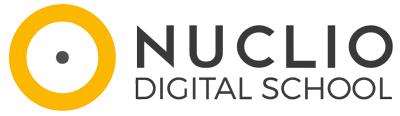

# Análisis de los Campeonatos Europeos de Halterofilia (2019-2024)

## Contexto y objetivo

Lift & Lead es una startup que estudia la apertura de centros especializados en halterofilia en Europa, ante el posible crecimiento del interés por este deporte.

El objetivo del proyecto es analizar los resultados de los Campeonatos Europeos de Halterofilia para identificar patrones de rendimiento, distribución de medallas por país y diferencias entre atletas masculinos y femeninos.

El análisis se desarrolla en dos fases:

1. **Análisis inicial (2019-2020):** exploración, limpieza y transformación de los datos disponibles.
2. **Ampliación del análisis (2019-2024):** recopilación de datos adicionales mediante web scraping, integración, validación y análisis exploratorio.

Los resultados permiten describir el panorama competitivo de la halterofilia europea, aunque no son suficientes por sí solos para demostrar una relación entre el crecimiento del CrossFit y la demanda de centros especializados.

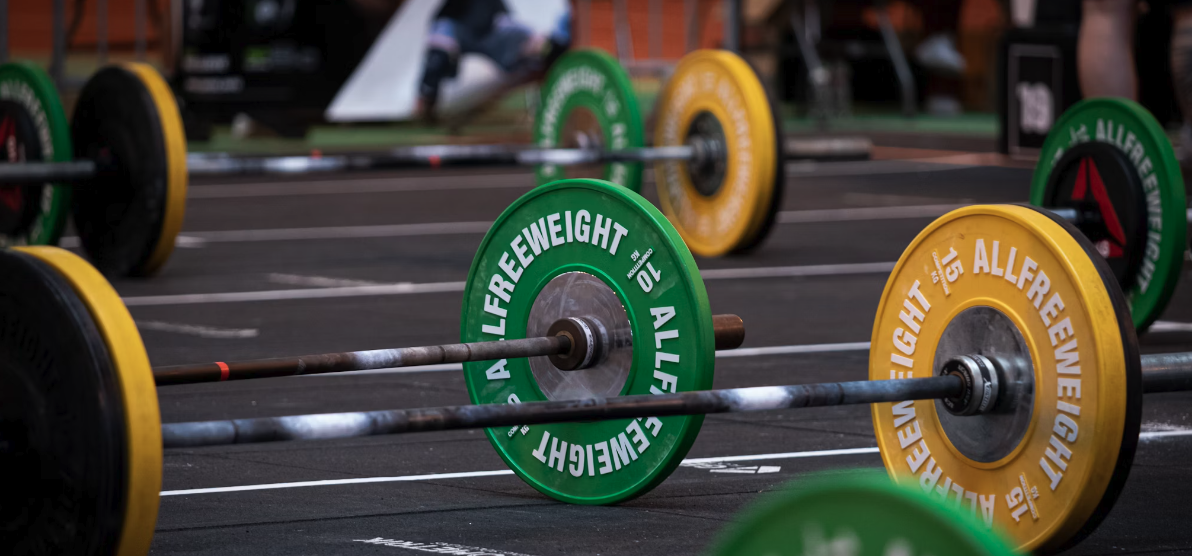

# **Parte 1.** Disponemos de la información

## Paso 1. Importar librerías

In [81]:
# Manipulación y análisis de datos
import pandas as pd
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# Gestión de archivos
import os

# Extracción de datos web
import requests

## Paso 2. Cargar datos

In [82]:
# Carpeta que contiene los archivos CSV
folder = "data"

# Listar únicamente los archivos CSV
lista_files = [
    file for file in os.listdir(folder)
    if file.endswith(".csv")
]

lista_files

FileNotFoundError: [WinError 3] El sistema no puede encontrar la ruta especificada: 'data'

In [ ]:
# Crear un diccionario vacío
dict_datos = {}

# Cargar los archivos CSV
for file in lista_files:
    clave = file.split(' ')[5]
    folder_file = os.path.join(folder, file)

    df = pd.read_csv(folder_file)

    dict_datos[clave] = df

dict_datos.keys()

dict_keys(['2019', '2020'])

## Paso 3. Exploración inicial

In [ ]:
# Comprobar el número de filas y columnas de cada DataFrame
for clave, df in dict_datos.items():
    print(f"{clave}: {df.shape}")

2019: (20, 6)
2020: (20, 6)


In [ ]:
# Visualizar las primeras filas de cada DataFrame
for clave, df in dict_datos.items():
    print(f"\n### Año {clave} ###")
    display(df.head())


### Año 2019 ###


,Eventos,Oro,Plata,Bronce,Año,Genero
0,55 kg (06.04),Mirco Scarantino Italia 116 + 145 = 261[n 1]​,Anguel Rusev Bulgaria 110 + 146 = 256[n 1]​,Muammer Şahin Turquía 112 + 135 = 247[n 1]​,2019,Masculino
1,61 kg (07.04),Henadz Laptseu Bielorrusia 133 + 153 = 286,Bünyamin Sezer Turquía 132 + 151 = 283,Ferdi Hardal Turquía 127 + 155 = 282,2019,Masculino
2,67 kg (08.04),Bernardin Matam Francia 137 + 175 = 312,Simon Brandhuber Alemania 146 + 165 = 311,Goga Chjeidze Georgia 139 + 169 = 308,2019,Masculino
3,73 kg (09.04),Bozhidar Andreev Bulgaria 153 + 192 = 345,Briken Calja Albania 156 + 183 = 339,Vadzim Lijarad Bielorrusia 153 + 182 = 335,2019,Masculino
4,81 kg (10.04),Antonino Pizzolato Italia 155 + 201 = 356,Piotr Asayonak Bielorrusia 159 + 196 = 355,Ritvars Suharevs Letonia 162 + 192 = 354,2019,Masculino



### Año 2020 ###


,Eventos,Oro,Plata,Bronce,Año,Genero
0,55 kg (04.04),Anguel Rusev Bulgaria 111 + 147 = 258[n 1]​,Valentin Iancu Rumania 108 + 140 = 248[n 1]​,Dmytro Voronovsky Ucrania 110 + 137 = 247[n 1]​,2020,Masculino
1,61 kg (04.04),Stilian Grozdev Bulgaria 136 + 160 = 296,Shota Mishvelidze Georgia 135 + 155 = 290,Ferdi Hardal Turquía 130 + 157 = 287,2020,Masculino
2,67 kg (05.04),Muhammed Özbek Turquía 145 + 178 = 323,Mirko Zanni Italia 148 + 170 = 318,Valentin Guenchev Bulgaria 138 + 177 = 315,2020,Masculino
3,73 kg (06.04),Daniyar İsmayilov Turquía 160 + 181 = 341,Marin Robu Moldavia 156 + 183 = 339,Briken Calja Albania 152 + 184 = 336,2020,Masculino
4,81 kg (07.04),Antonino Pizzolato Italia 164 + 206 = 370,Karlos Nasar Bulgaria 163 + 206 = 369,Ritvars Suharevs Letonia 157 + 190 = 347,2020,Masculino


In [ ]:
# Comprobar los tipos de datos de cada DataFrame
for clave, df in dict_datos.items():
    print(f"\n### Año {clave} ###")
    print(df.dtypes)


### Año 2019 ###
Eventos    object
Oro        object
Plata      object
Bronce     object
Año         int64
Genero     object
dtype: object

### Año 2020 ###
Eventos    object
Oro        object
Plata      object
Bronce     object
Año         int64
Genero     object
dtype: object


In [ ]:
# Identificar valores nulos por columna
for clave, df in dict_datos.items():
    print(f"\n### Año {clave} ###")
    print(df.isnull().sum())


### Año 2019 ###
Eventos    0
Oro        0
Plata      0
Bronce     0
Año        0
Genero     0
dtype: int64

### Año 2020 ###
Eventos    0
Oro        0
Plata      0
Bronce     0
Año        0
Genero     0
dtype: int64


In [ ]:
# Identificar filas duplicadas en cada DataFrame
for clave, df in dict_datos.items():
    print(f"{clave}: {df.duplicated().sum()} duplicados")

2019: 0 duplicados
2020: 0 duplicados


## Paso 4. Crear un único dataframe con los datos de 2019 y 2020

In [ ]:
# Unificar los datos de 2019 y 2020
df_total = pd.concat(dict_datos.values(), ignore_index=True)

# Comprobar las dimensiones
df_total.shape

(40, 6)

In [ ]:
# Comprobar el número de registros por año
df_total['Año'].value_counts()

Año
2019    20
2020    20
Name: count, dtype: int64

## Paso 5. Transformar los datos

En esta fase se transforma la estructura original de los datos, pasando las columnas de medallas (Oro, Plata y Bronce) a filas.

El objetivo es obtener un registro por atleta y medalla, facilitando la limpieza, integración y análisis posterior de los resultados.


In [ ]:
# Transformar las columnas de medallas en filas
df_transformado = pd.melt(
    df_total,
    id_vars=['Eventos', 'Año', 'Genero'],
    value_vars=['Oro', 'Plata', 'Bronce'],
    var_name='Medalla',
    value_name='Atleta'
)

df_transformado.head()

,Eventos,Año,Genero,Medalla,Atleta
0,55 kg (06.04),2019,Masculino,Oro,Mirco Scarantino Italia 116 + 145 = 261[n 1]​
1,61 kg (07.04),2019,Masculino,Oro,Henadz Laptseu Bielorrusia 133 + 153 = 286
2,67 kg (08.04),2019,Masculino,Oro,Bernardin Matam Francia 137 + 175 = 312
3,73 kg (09.04),2019,Masculino,Oro,Bozhidar Andreev Bulgaria 153 + 192 = 345
4,81 kg (10.04),2019,Masculino,Oro,Antonino Pizzolato Italia 155 + 201 = 356


In [ ]:
# Comprobar las dimensiones del DataFrame transformado
df_transformado.shape

(120, 5)

## Paso 6. Creación de columnas


- Fecha
- Nombre
- Apellido
- País
- Resultados
- Arrancada
- Dos tiempos
- Total

In [ ]:
# Extraer la fecha de la columna Eventos
df_transformado['Fecha'] = df_transformado['Eventos'].str.extract(r'\((.*?)\)')

# Visualizar el resultado
df_transformado[['Eventos', 'Fecha']].head()

,Eventos,Fecha
0,55 kg (06.04),06.04
1,61 kg (07.04),07.04
2,67 kg (08.04),08.04
3,73 kg (09.04),09.04
4,81 kg (10.04),10.04


In [ ]:
# Extraer la categoría de peso
df_transformado['Categoria'] = df_transformado['Eventos'].str.split('(').str[0].str.strip()

# Eliminar anotaciones y caracteres invisibles
df_transformado['Categoria'] = df_transformado['Categoria'].str.replace(
    r'\[.*?\]|\u200b', '', regex=True
).str.strip()

# Comprobar el resultado
df_transformado[['Eventos', 'Categoria', 'Fecha']].head()

,Eventos,Categoria,Fecha
0,55 kg (06.04),55 kg,06.04
1,61 kg (07.04),61 kg,07.04
2,67 kg (08.04),67 kg,08.04
3,73 kg (09.04),73 kg,09.04
4,81 kg (10.04),81 kg,10.04


Queremos identificar si todos los registros siguen el mismo formato o si existen diferencias, como nombres compuestos, países con varias palabras o anotaciones adicionales.

In [ ]:
# Extraer los resultados deportivos
df_transformado['Resultados'] = df_transformado['Atleta'].str.extract(r'(\d+\s*\+\s*\d+\s*=\s*\d+)')

# Comprobar la extracción
df_transformado[['Atleta', 'Resultados']].head()

,Atleta,Resultados
0,Mirco Scarantino Italia 116 + 145 = 261[n 1]​,116 + 145 = 261
1,Henadz Laptseu Bielorrusia 133 + 153 = 286,133 + 153 = 286
2,Bernardin Matam Francia 137 + 175 = 312,137 + 175 = 312
3,Bozhidar Andreev Bulgaria 153 + 192 = 345,153 + 192 = 345
4,Antonino Pizzolato Italia 155 + 201 = 356,155 + 201 = 356


In [ ]:
# Separar los resultados deportivos en tres columnas
df_transformado[['Arrancada', 'Dos tiempos', 'Total']] = df_transformado['Resultados'].str.extract(r'(\d+)\s*\+\s*(\d+)\s*=\s*(\d+)')

# Visualizar los resultados
df_transformado[['Resultados', 'Arrancada', 'Dos tiempos', 'Total']].head()

,Resultados,Arrancada,Dos tiempos,Total
0,116 + 145 = 261,116,145,261
1,133 + 153 = 286,133,153,286
2,137 + 175 = 312,137,175,312
3,153 + 192 = 345,153,192,345
4,155 + 201 = 356,155,201,356


In [ ]:
# Separar los datos personales de los resultados deportivos
df_transformado['Datos_personales'] = df_transformado['Atleta'].str.split(r'\d+\s*\+').str[0].str.strip()

# Visualizar los resultados
df_transformado[['Atleta', 'Datos_personales']].head(10)

,Atleta,Datos_personales
0,Mirco Scarantino Italia 116 + 145 = 261[n 1]​,Mirco Scarantino Italia
1,Henadz Laptseu Bielorrusia 133 + 153 = 286,Henadz Laptseu Bielorrusia
2,Bernardin Matam Francia 137 + 175 = 312,Bernardin Matam Francia
3,Bozhidar Andreev Bulgaria 153 + 192 = 345,Bozhidar Andreev Bulgaria
4,Antonino Pizzolato Italia 155 + 201 = 356,Antonino Pizzolato Italia
5,Hakob Mkrtchian Armenia 164 + 207 = 371,Hakob Mkrtchian Armenia
6,Yauheni Tsijantsou Bielorrusia 178 + 222 = 400,Yauheni Tsijantsou Bielorrusia
7,Dmytro Chumak Ucrania 175 + 216 = 391,Dmytro Chumak Ucrania
8,Simon Martirosian Armenia 192 + 235 = 427,Simon Martirosian Armenia
9,Lasha Talajadze Georgia 218 + 260 = 478,Lasha Talajadze Georgia


In [ ]:
# Lista de países identificados
paises = [
    'Albania', 'Alemania', 'Armenia', 'Austria', 'Azerbaiyán',
    'Bélgica', 'Bielorrusia', 'Bulgaria', 'España', 'Francia',
    'Georgia', 'Italia', 'Letonia', 'Moldavia', 'Polonia',
    'Reino Unido', 'Rumania', 'Rusia', 'Suecia', 'Turquía', 'Ucrania'
]

# Extraer el país de cada atleta
df_transformado['País'] = df_transformado['Datos_personales'].str.extract(
    r'(' + '|'.join(paises) + r')$'
)

# Comprobar los resultados
df_transformado[['Datos_personales', 'País']].head(10)

,Datos_personales,País
0,Mirco Scarantino Italia,Italia
1,Henadz Laptseu Bielorrusia,Bielorrusia
2,Bernardin Matam Francia,Francia
3,Bozhidar Andreev Bulgaria,Bulgaria
4,Antonino Pizzolato Italia,Italia
5,Hakob Mkrtchian Armenia,Armenia
6,Yauheni Tsijantsou Bielorrusia,Bielorrusia
7,Dmytro Chumak Ucrania,Ucrania
8,Simon Martirosian Armenia,Armenia
9,Lasha Talajadze Georgia,Georgia


In [ ]:
# Eliminar el país de los datos personales
df_transformado['Nombre_completo'] = df_transformado['Datos_personales'].str.replace(
    r'\s+' + '(' + '|'.join(paises) + r')$', '', regex=True
)

# Visualizar los resultados
df_transformado[['Datos_personales', 'Nombre_completo']].head()

,Datos_personales,Nombre_completo
0,Mirco Scarantino Italia,Mirco Scarantino
1,Henadz Laptseu Bielorrusia,Henadz Laptseu
2,Bernardin Matam Francia,Bernardin Matam
3,Bozhidar Andreev Bulgaria,Bozhidar Andreev
4,Antonino Pizzolato Italia,Antonino Pizzolato


In [ ]:
# Eliminar anotaciones numéricas entre corchetes
df_transformado['Nombre_completo'] = df_transformado['Nombre_completo'].str.replace(
    r'\[\d+\]', '', regex=True
).str.strip()

# Comprobar el registro de Lidia Valentín
df_transformado[df_transformado['Nombre_completo'].str.contains('Lidia')]

,Eventos,Año,Genero,Medalla,Atleta,Fecha,Categoria,Resultados,Arrancada,Dos tiempos,Total,Datos_personales,País,Nombre_completo
56,76 kg (11.04),2019,Femenino,Plata,Lidia Valentín[2]​ España 108 + 133 = 241,11.04,76 kg,108 + 133 = 241,108,133,241,Lidia Valentín[2]​ España,España,Lidia Valentín​


In [ ]:
# Separar el nombre y el apellido
df_transformado[['Nombre', 'Apellido']] = df_transformado['Nombre_completo'].str.split(' ', n=1, expand=True)

# Visualizar los resultados
df_transformado[['Nombre_completo', 'Nombre', 'Apellido']].head(10)

,Nombre_completo,Nombre,Apellido
0,Mirco Scarantino,Mirco,Scarantino
1,Henadz Laptseu,Henadz,Laptseu
2,Bernardin Matam,Bernardin,Matam
3,Bozhidar Andreev,Bozhidar,Andreev
4,Antonino Pizzolato,Antonino,Pizzolato
5,Hakob Mkrtchian,Hakob,Mkrtchian
6,Yauheni Tsijantsou,Yauheni,Tsijantsou
7,Dmytro Chumak,Dmytro,Chumak
8,Simon Martirosian,Simon,Martirosian
9,Lasha Talajadze,Lasha,Talajadze


## Paso 7. Filtrado de columnas y ordenación

Se seleccionan y ordenan las columnas relevantes para el análisis: género, categoría de peso, fecha, medalla, nombre, apellido, país, arrancada, dos tiempos y total.

De esta forma, se obtiene un conjunto de datos estructurado que facilita el análisis de los resultados deportivos.

In [ ]:
# Seleccionar y ordenar las columnas solicitadas
columnas = [
    'Genero', 'Categoria', 'Fecha', 'Medalla',
    'Nombre', 'Apellido', 'País',
    'Arrancada', 'Dos tiempos', 'Total'
]

df_final = df_transformado[columnas].copy()

# Renombrar las columnas
df_final = df_final.rename(columns={
    'Genero': 'Género',
    'Categoria': 'Categoría'
})

# Visualizar el resultado
df_final.head()

,Género,Categoría,Fecha,Medalla,Nombre,Apellido,País,Arrancada,Dos tiempos,Total
0,Masculino,55 kg,06.04,Oro,Mirco,Scarantino,Italia,116,145,261
1,Masculino,61 kg,07.04,Oro,Henadz,Laptseu,Bielorrusia,133,153,286
2,Masculino,67 kg,08.04,Oro,Bernardin,Matam,Francia,137,175,312
3,Masculino,73 kg,09.04,Oro,Bozhidar,Andreev,Bulgaria,153,192,345
4,Masculino,81 kg,10.04,Oro,Antonino,Pizzolato,Italia,155,201,356


## Paso 8. Tipo de datos

Se convierten las columnas a los tipos de datos adecuados para garantizar su correcta utilización en el análisis.

Las variables de categoría de peso y medalla se definen como categóricas, los resultados deportivos como numéricos enteros y las fechas como `datetime`.

Finalmente, se comprueban los tipos de datos para validar las conversiones.

In [ ]:
# Convertir columnas categóricas
df_final['Categoría'] = df_final['Categoría'].astype('category')
df_final['Medalla'] = df_final['Medalla'].astype('category')

# Convertir columnas numéricas
df_final['Arrancada'] = df_final['Arrancada'].astype('int64')
df_final['Dos tiempos'] = df_final['Dos tiempos'].astype('int64')
df_final['Total'] = df_final['Total'].astype('int64')

In [ ]:
# Incorporar el año original y convertir a fecha
df_final['Fecha'] = pd.to_datetime(
    df_final['Fecha'] + '.' + df_transformado['Año'].astype(str),
    format='%d.%m.%Y'
)

In [ ]:
# Comprobar los tipos de datos después de la conversión
df_final.dtypes

Género                 object
Categoría            category
Fecha          datetime64[ns]
Medalla              category
Nombre                 object
Apellido               object
País                   object
Arrancada               int64
Dos tiempos             int64
Total                   int64
dtype: object

## Paso 9. Ordenación de los datos

Se ordenan los registros por género, categoría de peso y tipo de medalla, estableciendo el orden Oro, Plata y Bronce.

Esta organización facilita la consulta y comparación de los resultados deportivos.

In [ ]:
# Definir el orden de las medallas
df_final['Medalla'] = pd.Categorical(
    df_final['Medalla'],
    categories=['Oro', 'Plata', 'Bronce'],
    ordered=True
)

# Crear una columna auxiliar para ordenar las categorías por peso
df_final['Peso'] = df_final['Categoría'].astype(str).str.extract(r'(\d+)').astype(int)

# Ordenar el DataFrame
df_final = df_final.sort_values(
    by=['Género', 'Peso', 'Medalla']
).drop(columns='Peso').reset_index(drop=True)

# Visualizar el resultado
df_final.head(10)

,Género,Categoría,Fecha,Medalla,Nombre,Apellido,País,Arrancada,Dos tiempos,Total
0,Femenino,45 kg,2019-04-06,Oro,Şaziye,Erdoğan,Turquía,75,88,163
1,Femenino,45 kg,2020-04-03,Oro,Nadezhda,Nguen,Bulgaria,72,83,155
2,Femenino,45 kg,2019-04-06,Plata,Ivana,Petrova,Bulgaria,69,89,158
3,Femenino,45 kg,2020-04-03,Plata,Ivana,Petrova,Bulgaria,67,85,152
4,Femenino,45 kg,2019-04-06,Bronce,Yuliya,Asayonak,Bielorrusia,69,81,150
5,Femenino,45 kg,2020-04-03,Bronce,Melisa,Güneş,Turquía,68,83,151
6,Femenino,49 kg,2019-04-06,Oro,Elena,Andrieș,Rumania,87,103,190
7,Femenino,49 kg,2020-04-03,Oro,Monica,Csengeri,Rumania,86,103,189
8,Femenino,49 kg,2019-04-06,Plata,Kristina,Sobol,Rusia,85,95,180
9,Femenino,49 kg,2020-04-03,Plata,Kristina,Sobol,Rusia,85,96,181


## Paso 10. Análisis exploratorio de datos (EDA)

Se realiza un análisis exploratorio para identificar patrones en los resultados deportivos, mediante:

- Estadísticas descriptivas de los pesos levantados.
- Distribución de medallas por país.
- Participación por género y categoría de peso.
- Comparación de los resultados deportivos entre géneros.

Los resultados permiten contextualizar los datos antes de profundizar en las preguntas del análisis

In [ ]:
# Obtener estadísticas descriptivas de las variables numéricas
df_final[['Arrancada', 'Dos tiempos', 'Total']].describe().round(2)

,Arrancada,Dos tiempos,Total
count,120.00,120.00,120.00
mean,129.60,157.39,286.99
std,38.60,45.19,83.57
min,67.00,81.00,150.00
25%,99.50,122.00,221.75
50%,114.50,145.00,257.00
75%,163.25,200.00,366.00
max,222.00,263.00,485.00


In [ ]:
# Contar los registros por género
df_final['Género'].value_counts()

Género
Femenino     60
Masculino    60
Name: count, dtype: int64

In [ ]:
# Contar el número de registros por país
df_final['País'].value_counts()

País
Rusia          20
Armenia        14
Bulgaria       10
Turquía         9
Bielorrusia     9
Rumania         9
Georgia         9
Ucrania         8
Italia          6
Reino Unido     6
Letonia         3
Francia         3
Alemania        2
Moldavia        2
Azerbaiyán      2
Bélgica         2
Albania         2
Suecia          1
España          1
Austria         1
Polonia         1
Name: count, dtype: int64

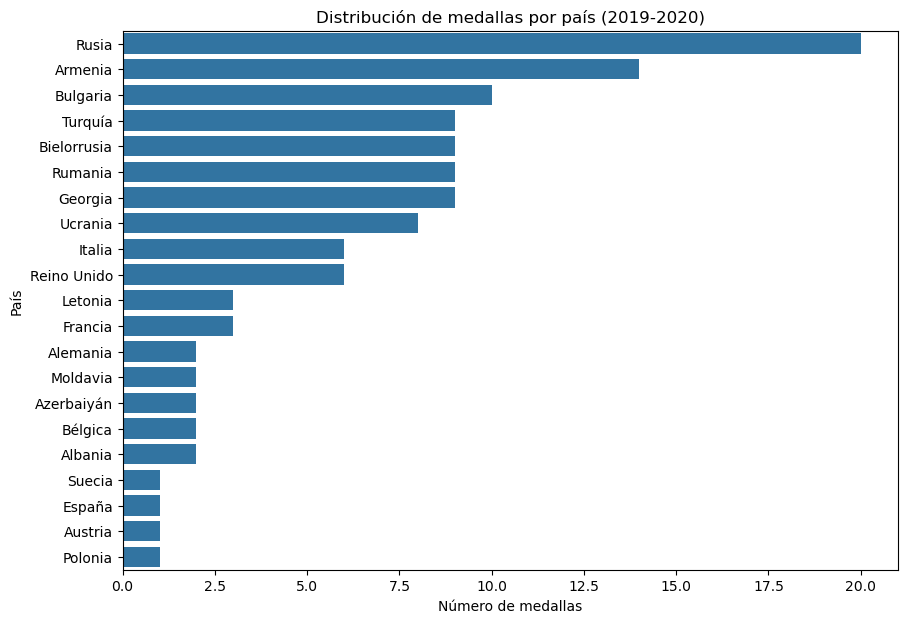

In [ ]:
# Distribución de medallas por país
medallas_pais = df_final['País'].value_counts()

plt.figure(figsize=(10, 7))
sns.barplot(x=medallas_pais.values, y=medallas_pais.index)

plt.title('Distribución de medallas por país (2019-2020)')
plt.xlabel('Número de medallas')
plt.ylabel('País')
plt.show()

El análisis muestra una distribución desigual de las medallas entre los 21 países representados. Rusia destaca con 20 medallas, seguida de Armenia (14) y Bulgaria (10). Los cinco países con mayor número de medallas concentran aproximadamente el 51,7 % del total, lo que evidencia una concentración de los resultados deportivos en determinadas naciones.

In [ ]:
# Contar las medallas por género y categoría de peso
df_final.groupby(['Género', 'Categoría'], observed=True).size()

Género     Categoría
Femenino   +87 kg       6
           45 kg        6
           49 kg        6
           55 kg        6
           59 kg        6
           64 kg        6
           71 kg        6
           76 kg        6
           81 kg        6
           87 kg        6
Masculino  +109 kg      6
           102 kg       6
           109 kg       6
           55 kg        6
           61 kg        6
           67 kg        6
           73 kg        6
           81 kg        6
           89 kg        6
           96 kg        6
dtype: int64

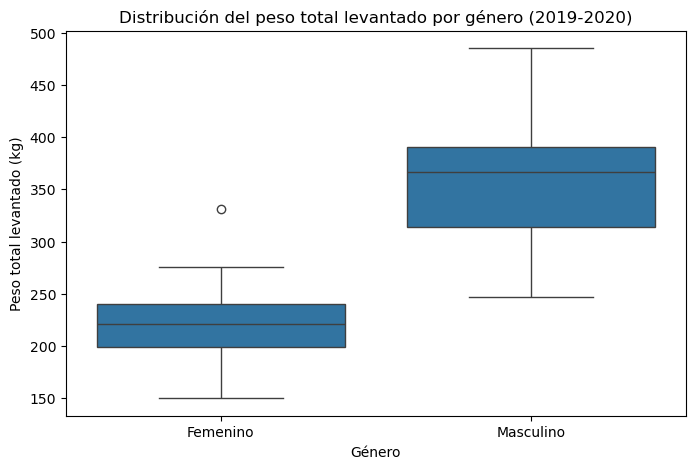

In [ ]:
# Comparar la distribución del peso total levantado por género
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_final, x='Género', y='Total')

plt.title('Distribución del peso total levantado por género (2019-2020)')
plt.xlabel('Género')
plt.ylabel('Peso total levantado (kg)')

plt.show()

El análisis del peso total levantado muestra diferencias entre los resultados masculinos y femeninos. La mediana masculina se sitúa aproximadamente en 365 kg, frente a los 220 kg de la femenina. Asimismo, los resultados masculinos presentan una mayor dispersión, mientras que en la distribución femenina se identifica un posible valor atípico. Estas diferencias deben interpretarse considerando las distintas categorías de peso de la competición.

## **Preguntas de análisis**

A partir de los datos preparados, se analizan tres cuestiones principales:

### 1. ¿Cómo se distribuyen las medallas de oro, plata y bronce entre los países participantes?

In [ ]:
# Contar las medallas de cada tipo por país
medallas_pais = pd.crosstab(df_final['País'], df_final['Medalla'])

# Ordenar las columnas por tipo de medalla
medallas_pais = medallas_pais[['Oro', 'Plata', 'Bronce']]

# Ordenar los países por número de medallas
medallas_pais = medallas_pais.sort_values(
    by=['Oro', 'Plata', 'Bronce'],
    ascending=False
)

medallas_pais

Medalla,Oro,Plata,Bronce
País,,,
Ucrania,5,2,1
Rusia,4,9,7
Bulgaria,4,5,1
Armenia,4,3,7
Rumania,4,2,3
Georgia,3,4,2
Bielorrusia,3,3,3
Italia,3,2,1
Turquía,3,1,5


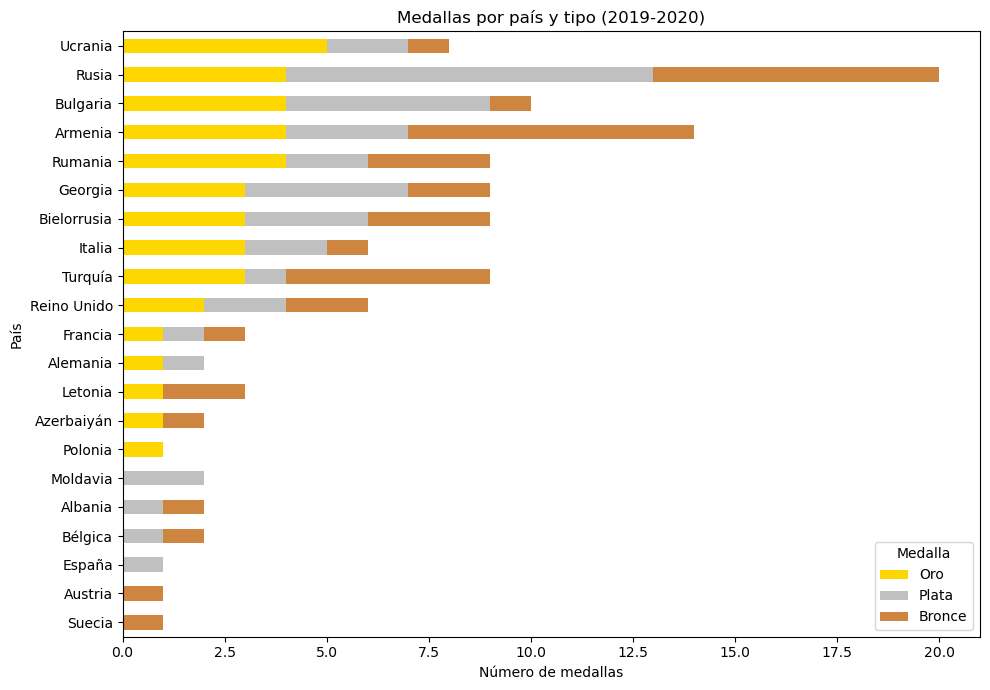

In [ ]:
# Visualizar las medallas por país y tipo
medallas_pais.plot(
    kind='barh',
    stacked=True,
    figsize=(10, 7),
    color=['gold', 'silver', 'peru']
)

plt.title('Medallas por país y tipo (2019-2020)')
plt.xlabel('Número de medallas')
plt.ylabel('País')
plt.gca().invert_yaxis()
plt.legend(title='Medalla')
plt.tight_layout()
plt.show()

Durante los campeonatos de 2019 y 2020, Rusia fue el país con mayor número de medallas (20), seguida de Armenia (14) y Bulgaria (10). Sin embargo, Ucrania destacó por conseguir el mayor número de medallas de oro (5), mientras que Rusia lideró las medallas de plata (9) y compartió con Armenia el mayor número de bronces (7).

Estos resultados muestran que el país con más medallas totales no necesariamente es el que obtiene más primeros puestos.

### 2. ¿Qué países presentan un reparto más equilibrado de medallas entre atletas femeninos y masculinos?

In [ ]:
# Contar las medallas por país y género
medallas_genero = pd.crosstab(df_final['País'], df_final['Género'])

medallas_genero

Género,Femenino,Masculino
País,,
Albania,0,2
Alemania,1,1
Armenia,2,12
Austria,1,0
Azerbaiyán,1,1
Bielorrusia,2,7
Bulgaria,3,7
Bélgica,2,0
España,1,0


In [ ]:
# Calcular la diferencia absoluta de medallas entre géneros
medallas_genero['Diferencia'] = abs(
    medallas_genero['Femenino'] - medallas_genero['Masculino']
)

# Calcular el total de medallas por país
medallas_genero['Total'] = medallas_genero['Femenino'] + medallas_genero['Masculino']

# Ordenar por menor diferencia y mayor número de medallas
medallas_genero = medallas_genero.sort_values(
    by=['Diferencia', 'Total'],
    ascending=[True, False]
)

medallas_genero

Género,Femenino,Masculino,Diferencia,Total
País,,,,
Alemania,1,1,0,2
Azerbaiyán,1,1,0,2
Moldavia,1,1,0,2
Francia,2,1,1,3
Letonia,1,2,1,3
Austria,1,0,1,1
España,1,0,1,1
Polonia,1,0,1,1
Suecia,1,0,1,1


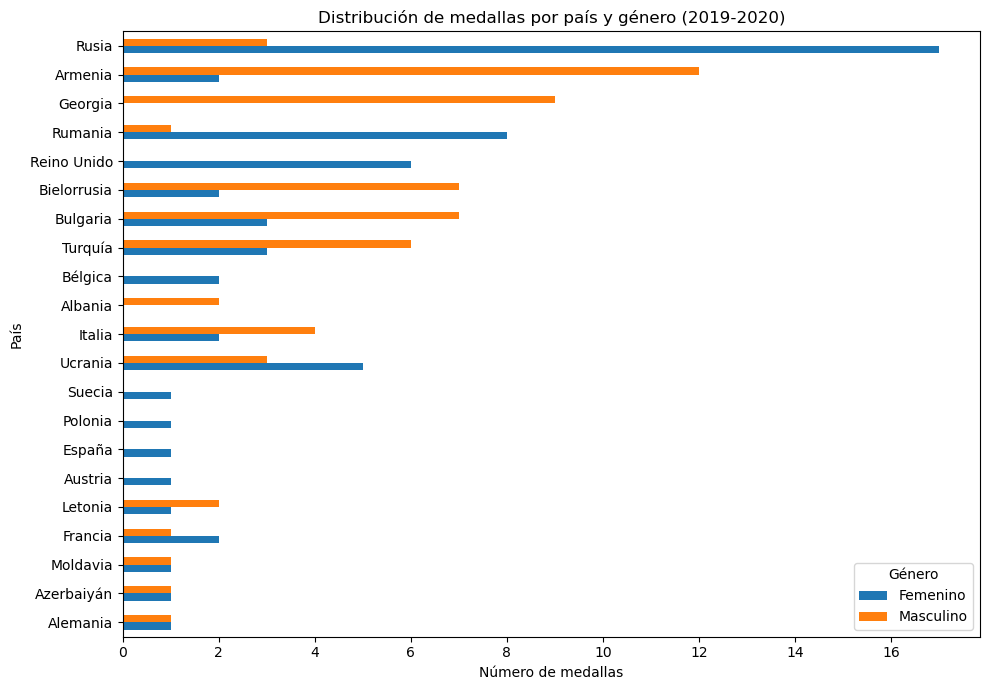

In [ ]:
# Comparar las medallas femeninas y masculinas por país
medallas_genero[['Femenino', 'Masculino']].plot(
    kind='barh',
    figsize=(10, 7)
)

plt.title('Distribución de medallas por país y género (2019-2020)')
plt.xlabel('Número de medallas')
plt.ylabel('País')
plt.legend(title='Género')
plt.tight_layout()
plt.show()

Alemania, Azerbaiyán y Moldavia presentan la mayor equidad en el reparto de medallas entre géneros, con una medalla femenina y una masculina cada uno.

No obstante, este equilibrio se observa sobre un número reducido de medallas. Entre los países con mayor representación en el medallero, Ucrania presenta un reparto relativamente equilibrado, con 5 medallas femeninas y 3 masculinas.

### 3. ¿En qué países existen menores diferencias en el promedio de peso total levantado entre ambos géneros?

In [ ]:
# Calcular el promedio de peso total levantado por país y género
promedio_genero = df_final.groupby(['País', 'Género'])['Total'].mean().unstack()

# Mostrar los resultados con dos decimales
promedio_genero.round(2)

Género,Femenino,Masculino
País,,
Albania,NaN,337.50
Alemania,222.00,311.00
Armenia,222.00,397.17
Austria,231.00,NaN
Azerbaiyán,211.00,379.00
Bielorrusia,196.00,362.43
Bulgaria,155.00,320.71
Bélgica,209.00,NaN
España,241.00,NaN


In [ ]:
# Conservar únicamente los países con resultados de ambos géneros
promedio_genero = promedio_genero.dropna()

# Calcular la diferencia absoluta entre los promedios
promedio_genero['Diferencia'] = abs(
    promedio_genero['Femenino'] - promedio_genero['Masculino']
)

# Ordenar de menor a mayor diferencia
promedio_genero = promedio_genero.sort_values('Diferencia')

# Mostrar los resultados
promedio_genero.round(2)

Género,Femenino,Masculino,Diferencia
País,,,
Rumania,213.00,248.00,35.00
Alemania,222.00,311.00,89.00
Francia,220.50,312.00,91.50
Moldavia,245.00,339.00,94.00
Ucrania,242.40,348.33,105.93
Turquía,185.67,293.83,108.17
Italia,198.50,326.25,127.75
Letonia,221.00,350.50,129.50
Bulgaria,155.00,320.71,165.71


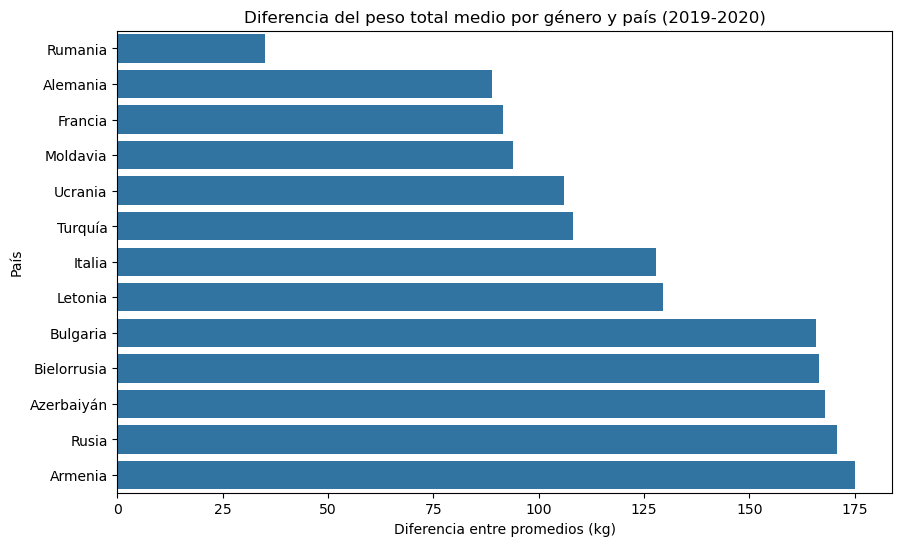

In [ ]:
# Visualizar la diferencia de promedios entre géneros por país
plt.figure(figsize=(10, 6))

sns.barplot(
    x=promedio_genero['Diferencia'],
    y=promedio_genero.index
)

plt.title('Diferencia del peso total medio por género y país (2019-2020)')
plt.xlabel('Diferencia entre promedios (kg)')
plt.ylabel('País')

plt.show()

Rumania presenta la menor diferencia entre el promedio de peso total levantado por atletas femeninos (213 kg) y masculinos (248 kg), con una diferencia absoluta de 35 kg. Le siguen Alemania (89 kg) y Francia (91,50 kg).

No obstante, el resultado de Rumania debe interpretarse con cautela, ya que el promedio masculino se basa en un único registro. Además, las diferencias corresponden a kilogramos absolutos y no están ajustadas por categoría de peso.

# **Fase 2.** Web scraping

## Paso 1. Cargar datos

In [ ]:
# Definir la cabecera HTTP para acceder a las páginas de Wikipedia.

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3'
}

# Generar las URL de los campeonatos de 2021 a 2024.

url = 'https://es.wikipedia.org/wiki/Campeonato_Europeo_de_Halterofilia_de_'

list_years = np.arange(2021, 2025)

list_urls = [url + str(year) for year in list_years]

list_urls

['https://es.wikipedia.org/wiki/Campeonato_Europeo_de_Halterofilia_de_2021',
 'https://es.wikipedia.org/wiki/Campeonato_Europeo_de_Halterofilia_de_2022',
 'https://es.wikipedia.org/wiki/Campeonato_Europeo_de_Halterofilia_de_2023',
 'https://es.wikipedia.org/wiki/Campeonato_Europeo_de_Halterofilia_de_2024']

In [ ]:
# Extraer las tablas HTML de cada campeonato y almacenarlas en un diccionario.

dict_datos_scraping = {}

for url in list_urls:
    year = url.split('_')[-1]

    page = requests.get(url, headers=headers, timeout =15)

    print(f"Año {year}: Estado HTTP {page.status_code}")

    if page.status_code == 200:
        html = page.text
        dict_datos_scraping[year] = pd.read_html(html)

        print(f"Tablas encontradas: {len(dict_datos_scraping[year])}")

Año 2021: Estado HTTP 200
Tablas encontradas: 7


C:\Users\NACHO CHAMBO\AppData\Local\Temp\ipykernel_3888\1196183478.py:14: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  dict_datos_scraping[year] = pd.read_html(html)


Año 2022: Estado HTTP 200
Tablas encontradas: 7


C:\Users\NACHO CHAMBO\AppData\Local\Temp\ipykernel_3888\1196183478.py:14: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  dict_datos_scraping[year] = pd.read_html(html)


Año 2023: Estado HTTP 200
Tablas encontradas: 7


C:\Users\NACHO CHAMBO\AppData\Local\Temp\ipykernel_3888\1196183478.py:14: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  dict_datos_scraping[year] = pd.read_html(html)


Año 2024: Estado HTTP 200
Tablas encontradas: 7


C:\Users\NACHO CHAMBO\AppData\Local\Temp\ipykernel_3888\1196183478.py:14: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  dict_datos_scraping[year] = pd.read_html(html)


In [ ]:
# Seleccionar las tablas masculinas y femeninas de cada año.

dict_resultados = {}

for year, tablas in dict_datos_scraping.items():
    
    if len(tablas) < 4:
        raise ValueError(
            f"Año {year}: no se encontraron las tablas esperadas."
    )

    df_masculino = tablas[2].copy()
    df_masculino['Genero'] = 'Masculino'
    df_masculino['Año'] = year

    df_femenino = tablas[3].copy()
    df_femenino['Genero'] = 'Femenino'
    df_femenino['Año'] = year

    dict_resultados[year] = pd.concat(
        [df_masculino, df_femenino],
        ignore_index=True
    )

In [ ]:
# Comprobar las dimensiones de los datos extraídos por año.

for year, df in dict_resultados.items():
    print(f"Año {year}: {df.shape}")

Año 2021: (20, 6)
Año 2022: (20, 6)
Año 2023: (20, 6)
Año 2024: (20, 6)


In [ ]:
# Renombrar las columnas de los campeonatos para unificar su estructura.

for year, df in dict_resultados.items():
    dict_resultados[year] = df.rename(columns={
        'Evento': 'Eventos',
        'Unnamed: 1': 'Oro',
        'Unnamed: 2': 'Plata',
        'Unnamed: 3': 'Bronce'
    })

## Paso 2. Exploración inicial

In [ ]:
# Revisar los tipos de datos, valores nulos y duplicados de cada campeonato.

for year, df in dict_resultados.items():
    print(f"\n*************** AÑO {year} ***************")

    print("\nTipos de datos:")
    print(df.dtypes)

    print("\nValores nulos:")
    print(df.isnull().sum())

    print("\nFilas duplicadas:")
    print(df.duplicated().sum())


*************** AÑO 2021 ***************

Tipos de datos:
Eventos    object
Oro        object
Plata      object
Bronce     object
Genero     object
Año        object
dtype: object

Valores nulos:
Eventos    0
Oro        0
Plata      0
Bronce     0
Genero     0
Año        0
dtype: int64

Filas duplicadas:
0

*************** AÑO 2022 ***************

Tipos de datos:
Eventos    object
Oro        object
Plata      object
Bronce     object
Genero     object
Año        object
dtype: object

Valores nulos:
Eventos    0
Oro        0
Plata      0
Bronce     0
Genero     0
Año        0
dtype: int64

Filas duplicadas:
0

*************** AÑO 2023 ***************

Tipos de datos:
Eventos    object
Oro        object
Plata      object
Bronce     object
Genero     object
Año        object
dtype: object

Valores nulos:
Eventos    0
Oro        0
Plata      0
Bronce     0
Genero     0
Año        0
dtype: int64

Filas duplicadas:
0

*************** AÑO 2024 ***************

Tipos de datos:
Eventos    obj

La exploración inicial de los campeonatos de 2021 a 2024 confirma que los cuatro conjuntos de datos presentan una estructura homogénea, sin valores nulos ni registros completamente duplicados. Los tipos de datos son coherentes con el formato original, por lo que no se requieren tratamientos adicionales en este apartado.

## Paso 3. Crear un único dataframe con los datos de 2019, 2020, 2021, 2022, 2023 y 2024

In [ ]:
# Integrar los datos originales y los obtenidos mediante web scraping.

df_total_2019_2024 = pd.concat(
    list(dict_datos.values()) + list(dict_resultados.values()),
    ignore_index=True
)

# Unificar el tipo de dato de la columna Año.

df_total_2019_2024['Año'] = df_total_2019_2024['Año'].astype('int64')

# Excluir los registros de 2020 para evitar duplicar el campeonato celebrado en 2021.

df_total_2019_2024 = df_total_2019_2024[
    df_total_2019_2024['Año'] != 2020
].copy()

In [ ]:
# Comprobar las dimensiones y distribución de registros por año.

print(df_total_2019_2024.shape)

print(df_total_2019_2024['Año'].value_counts().sort_index())

(100, 6)
Año
2019    20
2021    20
2022    20
2023    20
2024    20
Name: count, dtype: int64


Tratamiento de la duplicidad entre 2020 y 2021

Durante la validación del conjunto de datos ampliado se identificaron 57 coincidencias exactas entre los 60 registros de los años 2020 y 2021. Tras revisar la información, se comprobó que el Campeonato Europeo previsto para 2020 fue aplazado a 2021 debido a la pandemia.

Las tres diferencias restantes corresponden a la categoría femenina de 59 kg, cuya clasificación fue modificada tras la descalificación de Boyanka Kostova.

Por este motivo, se decidió conservar los resultados revisados de 2021 y excluir los registros de 2020 únicamente del análisis ampliado, evitando contabilizar dos veces una misma competición. Los datos originales y el análisis de la primera fase se mantienen sin modificaciones.

Fuentes de verificación:

- **Federación Internacional de Halterofilia (IWF):** confirma que el Campeonato Europeo previsto para 2020 fue aplazado a 2021 debido a la pandemia. https://iwf.sport/2020/08/31/iwf-events-affected-covid-19-pandemic-iwf-competition-calendar-2020-update-2/

- **Agencia Internacional de Controles (ITA):** confirma la descalificación de Boyanka Kostova y la anulación de sus resultados del Campeonato Europeo de 2021. https://ita.sport/news/the-ita-issues-decision-sanctioning-azerbaijan-weightlifter-boyanka-kostova-to-8-year-period-of-ineligibility/

## Paso 4. Transformar los datos

Se transforma el conjunto de datos de 2019 a 2024 mediante `pd.melt()`, convirtiendo las columnas de medallas (Oro, Plata y Bronce) en filas.

El resultado contiene las columnas Eventos, Año, Genero, Medalla y Atleta, manteniendo una estructura homogénea para continuar con la preparación y el análisis de los datos.

In [ ]:
# Transformar las columnas de medallas en filas.

df_transformado_2019_2024 = pd.melt(
    df_total_2019_2024,
    id_vars=['Eventos', 'Año', 'Genero'],
    value_vars=['Oro', 'Plata', 'Bronce'],
    var_name='Medalla',
    value_name='Atleta'
)

In [ ]:
# Comprobar las dimensiones y visualizar los primeros registros.

print(df_transformado_2019_2024.shape)

display(df_transformado_2019_2024.head())

(300, 5)


,Eventos,Año,Genero,Medalla,Atleta
0,55 kg (06.04),2019,Masculino,Oro,Mirco Scarantino Italia 116 + 145 = 261[n 1]​
1,61 kg (07.04),2019,Masculino,Oro,Henadz Laptseu Bielorrusia 133 + 153 = 286
2,67 kg (08.04),2019,Masculino,Oro,Bernardin Matam Francia 137 + 175 = 312
3,73 kg (09.04),2019,Masculino,Oro,Bozhidar Andreev Bulgaria 153 + 192 = 345
4,81 kg (10.04),2019,Masculino,Oro,Antonino Pizzolato Italia 155 + 201 = 356


## Paso 5. Creación de columnas

A partir de los datos extraídos, se generan las variables necesarias para el análisis:

- **Fecha y categoría:** información correspondiente a cada evento deportivo.
- **Nombre, apellido y país:** identificación y representación de los atletas.
- **Arrancada, dos tiempos y total:** resultados deportivos expresados en kilogramos.

Para ello, se utilizan operaciones de texto y expresiones regulares que permiten separar la información almacenada originalmente en una misma columna.


In [ ]:
# Extraer la fecha de celebración de cada evento.

df_transformado_2019_2024['Fecha'] = df_transformado_2019_2024['Eventos'].str.extract(r'\((.*?)\)')

In [ ]:
# Comprobar los valores nulos y una muestra de fechas por año.

print("Valores nulos:", df_transformado_2019_2024['Fecha'].isnull().sum())

print(df_transformado_2019_2024.groupby('Año')['Fecha'].first())

Valores nulos: 0
Año
2019    06.04
2021    04.04
2022    29.05
2023    16.04
2024    13.02
Name: Fecha, dtype: object


In [ ]:
# Extraer y limpiar las categorías de peso.

df_transformado_2019_2024['Categoria'] = df_transformado_2019_2024['Eventos'].str.split('(').str[0]

df_transformado_2019_2024['Categoria'] = df_transformado_2019_2024['Categoria'].str.replace(
    r'\[.*?\]|\u200b|\xa0', ' ', regex=True
).str.strip()

In [ ]:
# Extraer los resultados deportivos de cada atleta.

df_transformado_2019_2024['Resultados'] = df_transformado_2019_2024['Atleta'].str.extract(
    r'(\d+\s*\+\s*\d+\s*=\s*\d+)'
)

df_transformado_2019_2024[['Arrancada', 'Dos tiempos', 'Total']] = df_transformado_2019_2024['Resultados'].str.extract(
    r'(\d+)\s*\+\s*(\d+)\s*=\s*(\d+)'
)

In [ ]:
# Extraer los datos personales del atleta, separándolos de sus resultados deportivos.

df_transformado_2019_2024['Datos_personales'] = df_transformado_2019_2024['Atleta'].str.split(
    r'\d+\s*\+'
).str[0].str.strip()

In [ ]:
# Eliminar las anotaciones de referencia de los datos personales.

df_transformado_2019_2024['Datos_personales'] = df_transformado_2019_2024['Datos_personales'].str.replace(
    r'\[a 1\]', '', regex=True
).str.strip()

In [ ]:
# Definir los países y la designación AIN presentes en los campeonatos.

paises = [
    'Albania', 'Alemania', 'Armenia', 'Austria', 'Azerbaiyán',
    'Bélgica', 'Bielorrusia', 'Bulgaria', 'España', 'Francia',
    'Georgia', 'Italia', 'Letonia', 'Moldavia', 'Polonia',
    'Reino Unido', 'Rumania', 'Rusia', 'Suecia', 'Turquía',
    'Ucrania', 'Noruega', 'Israel', 'Serbia', 'Irlanda',
    'Finlandia', 'AIN'
]

In [ ]:
# Extraer el país o la designación de representación de cada atleta.

df_transformado_2019_2024['País'] = df_transformado_2019_2024['Datos_personales'].str.extract(
    r'(' + '|'.join(paises) + r')$'
)

In [ ]:
# Extraer el nombre completo eliminando el país o designación del atleta.

df_transformado_2019_2024['Nombre_completo'] = df_transformado_2019_2024['Datos_personales'].str.replace(
    r'\s+' + '(' + '|'.join(paises) + r')$', '', regex=True
)

In [ ]:
# Eliminar anotaciones y espacios innecesarios de los nombres.

df_transformado_2019_2024['Nombre_completo'] = df_transformado_2019_2024['Nombre_completo'].str.replace(
    r'\[\d+\]', '', regex=True
).str.strip()

In [ ]:
# Separar el nombre y los apellidos de cada atleta.

df_transformado_2019_2024[['Nombre', 'Apellido']] = df_transformado_2019_2024['Nombre_completo'].str.split(
    ' ', n=1, expand=True
)

## Paso 6. Filtrado de columnas y ordenación

Se seleccionan las columnas relevantes y se establece una estructura homogénea para los resultados de los campeonatos de 2019 a 2024.

El conjunto de datos final incluye información sobre el género, categoría de peso, fecha, medalla, atleta, país y resultados de los levantamientos.

In [ ]:
# Seleccionar las columnas necesarias en el orden solicitado.

columnas = [
    'Genero', 'Categoria', 'Fecha', 'Medalla',
    'Nombre', 'Apellido', 'País',
    'Arrancada', 'Dos tiempos', 'Total'
]

df_final_2019_2024 = df_transformado_2019_2024[columnas].copy()

df_final_2019_2024 = df_final_2019_2024.rename(columns={
    'Genero': 'Género',
    'Categoria': 'Categoría'
})

## Paso 7. Tipo de datos

Se convierten las variables a los tipos de datos adecuados para garantizar su correcta utilización en el análisis.

Las columnas de categoría de peso y medalla se convierten a tipo categórico, los resultados deportivos a valores enteros y las fechas a formato `datetime`.

Además, se valida que la suma de los resultados de arrancada y dos tiempos coincida con el total registrado, identificando posibles inconsistencias en los datos.

In [ ]:
# Convertir las columnas categóricas y numéricas a sus tipos correspondientes.

df_final_2019_2024['Categoría'] = df_final_2019_2024['Categoría'].astype('category')
df_final_2019_2024['Medalla'] = df_final_2019_2024['Medalla'].astype('category')

df_final_2019_2024['Arrancada'] = df_final_2019_2024['Arrancada'].astype('int64')
df_final_2019_2024['Dos tiempos'] = df_final_2019_2024['Dos tiempos'].astype('int64')
df_final_2019_2024['Total'] = df_final_2019_2024['Total'].astype('int64')

In [ ]:
# Incorporar el año y convertir la fecha a formato datetime.

df_final_2019_2024['Fecha'] = pd.to_datetime(
    df_final_2019_2024['Fecha'] + '.' + df_transformado_2019_2024['Año'].astype(str),
    format='%d.%m.%Y'
)

In [ ]:
# Identificar los registros donde la suma de los levantamientos no coincide con el total.

df_final_2019_2024[
    df_final_2019_2024['Arrancada'] +
    df_final_2019_2024['Dos tiempos'] !=
    df_final_2019_2024['Total']
]

,Género,Categoría,Fecha,Medalla,Nombre,Apellido,País,Arrancada,Dos tiempos,Total
52,Femenino,55 kg,2022-05-29,Oro,Kamila,Konotop,Ucrania,94,11,207


Corrección de una inconsistencia en los resultados deportivos

Durante la validación se detectó una inconsistencia en el resultado de Kamila Konotop (2022), categoría femenina de 55 kg. El dato extraído de Wikipedia indicaba 94 kg en arrancada, 11 kg en dos tiempos y 207 kg en total.

Tras consultar los resultados oficiales de la Federación Europea de Halterofilia (EWF), se confirmó que el valor correcto de dos tiempos es 113 kg. Se corrigió únicamente este dato, conservando el resto de la información.

**Fuente:** [Resultados oficiales del Campeonato Europeo de Halterofilia de 2022 — EWF](https://ewf.sport/wp-content/uploads/2022/06/Results_Book_2022_European_ALB.pdf)

In [ ]:
# Corregir el resultado de Kamila Konotop (2022) según los datos oficiales de la EWF.

df_final_2019_2024.loc[
    (df_final_2019_2024['Nombre'] == 'Kamila') &
    (df_final_2019_2024['Apellido'] == 'Konotop') &
    (df_final_2019_2024['Fecha'].dt.year == 2022),
    'Dos tiempos'
] = 113

In [ ]:
# Comprobar que todos los resultados deportivos son coherentes.

print("Resultados inconsistentes:", (
    df_final_2019_2024['Arrancada'] +
    df_final_2019_2024['Dos tiempos'] !=
    df_final_2019_2024['Total']
).sum())

Resultados inconsistentes: 0


## Paso 8. Ordenación de los datos 

Se ordenan los registros por género, categoría de peso, tipo de medalla y fecha.

Para las medallas se establece el orden Oro, Plata y Bronce, facilitando la consulta y comparación de los resultados de los distintos campeonatos.

In [ ]:
# Ordenar los registros por género, categoría, medalla y fecha.

df_final_2019_2024['Medalla'] = pd.Categorical(
    df_final_2019_2024['Medalla'],
    categories=['Oro', 'Plata', 'Bronce'],
    ordered=True
)

df_final_2019_2024['Peso'] = df_final_2019_2024['Categoría'].astype(str).str.extract(r'(\d+)').astype(int)

df_final_2019_2024 = df_final_2019_2024.sort_values(
    by=['Género', 'Peso', 'Medalla', 'Fecha']
).drop(columns='Peso').reset_index(drop=True)

## Paso 9. Análisis exploratorio de datos (EDA)

Se realiza un análisis exploratorio de los resultados de los Campeonatos Europeos de Halterofilia entre 2019 y 2024, con el objetivo de identificar patrones y diferencias en el rendimiento deportivo.

El análisis incluye:

- Estadísticas descriptivas de los pesos levantados.
- Distribución de medallas por país.
- Distribución de resultados por año, género y categoría de peso.
- Comparación del peso total levantado entre géneros.

Estos resultados permiten contextualizar las principales características del conjunto de datos antes de abordar las preguntas de análisis.

In [ ]:
# Obtener las estadísticas descriptivas de los resultados deportivos.

df_final_2019_2024[['Arrancada', 'Dos tiempos', 'Total']].describe().round(2)

,Arrancada,Dos tiempos,Total
count,300.00,300.00,300.00
mean,128.23,155.85,284.07
std,37.81,44.41,81.98
min,65.00,81.00,150.00
25%,99.00,120.00,221.00
50%,114.00,141.00,254.50
75%,162.25,196.00,360.75
max,222.00,263.00,485.00


El análisis descriptivo de los 300 registros muestra un peso total medio de 284,07 kg y una mediana de 254,50 kg. La desviación estándar de 81,98 kg refleja una dispersión considerable en los resultados, influida por las diferencias entre géneros y categorías de peso. Por tanto, estos valores deben interpretarse como una descripción general del conjunto de datos y no como una medida comparable del rendimiento individual.

In [ ]:
# Analizar la distribución de registros por año y género.

pd.crosstab(
    df_final_2019_2024['Fecha'].dt.year,
    df_final_2019_2024['Género']
)

Género,Femenino,Masculino
Fecha,,
2019,30,30
2021,30,30
2022,30,30
2023,30,30
2024,30,30


In [ ]:
# Contar el número total de medallas por país.

df_final_2019_2024['País'].value_counts()

País
Armenia        44
Turquía        28
Ucrania        28
Bulgaria       28
Georgia        24
Rusia          21
Italia         19
Rumania        16
Reino Unido    11
España         10
Bielorrusia     9
Francia         9
Moldavia        7
Alemania        7
Letonia         7
Polonia         6
Noruega         5
Bélgica         4
AIN             4
Albania         3
Suecia          2
Austria         2
Azerbaiyán      2
Finlandia       1
Israel          1
Irlanda         1
Serbia          1
Name: count, dtype: int64

In [ ]:
# Analizar la distribución de medallas por género y categoría de peso.

df_final_2019_2024.groupby(
    ['Género', 'Categoría'],
    observed=True
).size()

Género     Categoría
Femenino   +87 kg       15
           45 kg        15
           49 kg        15
           55 kg        15
           59 kg        15
           64 kg        15
           71 kg        15
           76 kg        15
           81 kg        15
           87 kg        15
Masculino  +109 kg      15
           102 kg       15
           109 kg       15
           55 kg        15
           61 kg        15
           67 kg        15
           73 kg        15
           81 kg        15
           89 kg        15
           96 kg        15
dtype: int64

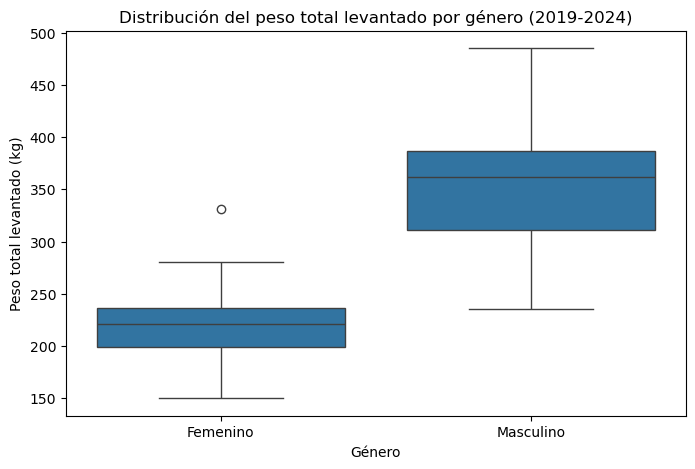

In [ ]:
# Visualizar la distribución del peso total levantado por género.

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_final_2019_2024, x='Género', y='Total')

plt.title('Distribución del peso total levantado por género (2019-2024)')
plt.xlabel('Género')
plt.ylabel('Peso total levantado (kg)')

plt.show()

El análisis del peso total levantado muestra una mediana aproximada de 360 kg en la categoría masculina y de 220 kg en la femenina. Los resultados masculinos presentan una mayor dispersión, mientras que en los femeninos se identifica un posible valor atípico cercano a 330 kg. Estas diferencias deben interpretarse considerando que se analizan kilogramos absolutos correspondientes a distintas categorías de peso, por lo que no constituyen una comparación directa del rendimiento deportivo.

## **Preguntas de análisis**

### ¿Cuántas medallas de cada tipo (oro, plata y bronce) ha ganado cada país en la competición? (Sin considerar el género)

In [ ]:
# Calcular las medallas de oro, plata y bronce obtenidas por cada país.

medallas_pais = pd.crosstab(
    df_final_2019_2024['País'],
    df_final_2019_2024['Medalla']
)

medallas_pais = medallas_pais[['Oro', 'Plata', 'Bronce']]

medallas_pais = medallas_pais.sort_values(
    by=['Oro', 'Plata', 'Bronce'],
    ascending=False
)

medallas_pais

Medalla,Oro,Plata,Bronce
País,,,
Bulgaria,15,8,5
Armenia,14,13,17
Ucrania,12,10,6
Rumania,9,3,4
Turquía,8,9,11
Italia,8,8,3
Georgia,6,13,5
Rusia,5,8,8
Reino Unido,5,2,4


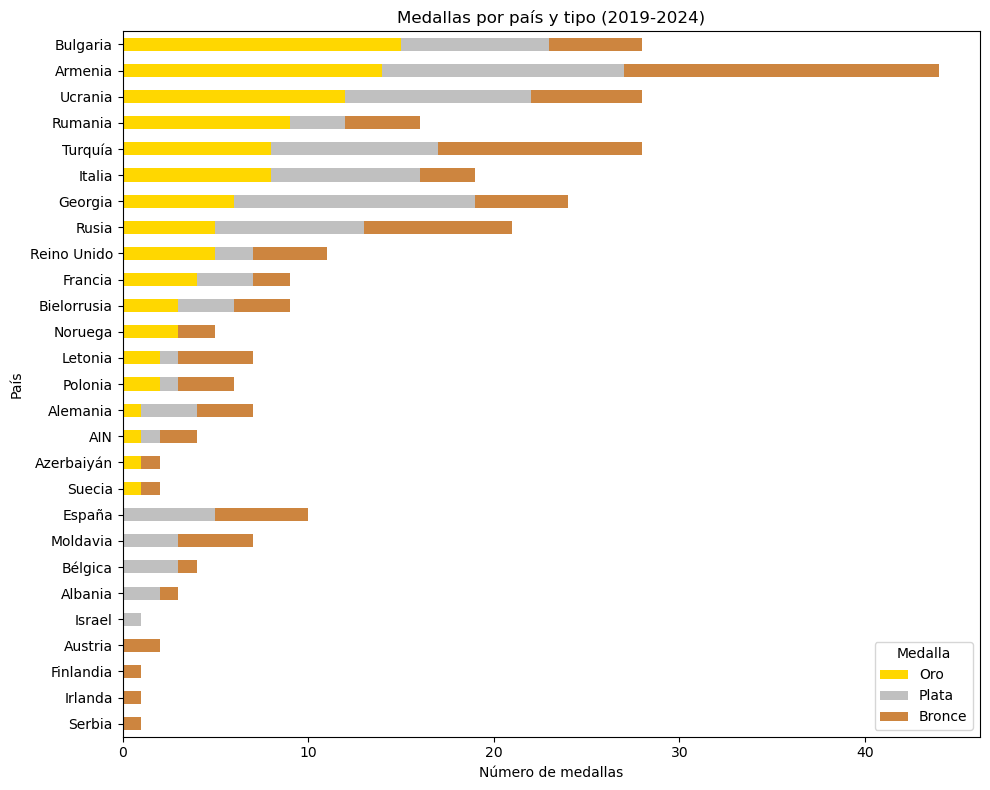

In [ ]:
# Visualizar las medallas de oro, plata y bronce obtenidas por país.

medallas_pais.plot(
    kind='barh',
    stacked=True,
    figsize=(10, 8),
    color=['gold', 'silver', 'peru']
)

plt.title('Medallas por país y tipo (2019-2024)')
plt.xlabel('Número de medallas')
plt.ylabel('País')
plt.gca().invert_yaxis()
plt.legend(title='Medalla')
plt.tight_layout()
plt.show()

Durante el periodo analizado (2019-2024), Bulgaria lidera la clasificación por medallas de oro, con 15, mientras que Armenia acumula el mayor número de medallas totales, con 44. Armenia y Georgia comparten el liderazgo en medallas de plata, con 13 cada una, y Armenia destaca también en bronces, con 17.

Estos resultados evidencian que el país con más medallas de oro no coincide necesariamente con el que acumula más medallas en el conjunto de las competiciones.

### ¿Qué país ha logrado la mayor equidad en términos de éxito entre sus atletas femeninos y masculinos?

In [ ]:
# Calcular la distribución de medallas por género, su diferencia y los porcentajes por país.

medallas_genero = pd.crosstab(
    df_final_2019_2024['País'],
    df_final_2019_2024['Género']
)

medallas_genero['Diferencia'] = abs(
    medallas_genero['Femenino'] - medallas_genero['Masculino']
)

medallas_genero['Total'] = medallas_genero['Femenino'] + medallas_genero['Masculino']

medallas_genero['% Femenino'] = (
    medallas_genero['Femenino'] / medallas_genero['Total'] * 100
).round(2)

medallas_genero['% Masculino'] = (
    medallas_genero['Masculino'] / medallas_genero['Total'] * 100
).round(2)

medallas_genero = medallas_genero.sort_values(
    by=['Diferencia', 'Total'],
    ascending=[True, False]
)

medallas_genero

Género,Femenino,Masculino,Diferencia,Total,% Femenino,% Masculino
País,,,,,,
Alemania,4,3,1,7,57.14,42.86
Letonia,3,4,1,7,42.86,57.14
Moldavia,3,4,1,7,42.86,57.14
Finlandia,1,0,1,1,100.00,0.00
Irlanda,1,0,1,1,100.00,0.00
Israel,1,0,1,1,100.00,0.00
Serbia,1,0,1,1,100.00,0.00
España,4,6,2,10,40.00,60.00
AIN,1,3,2,4,25.00,75.00


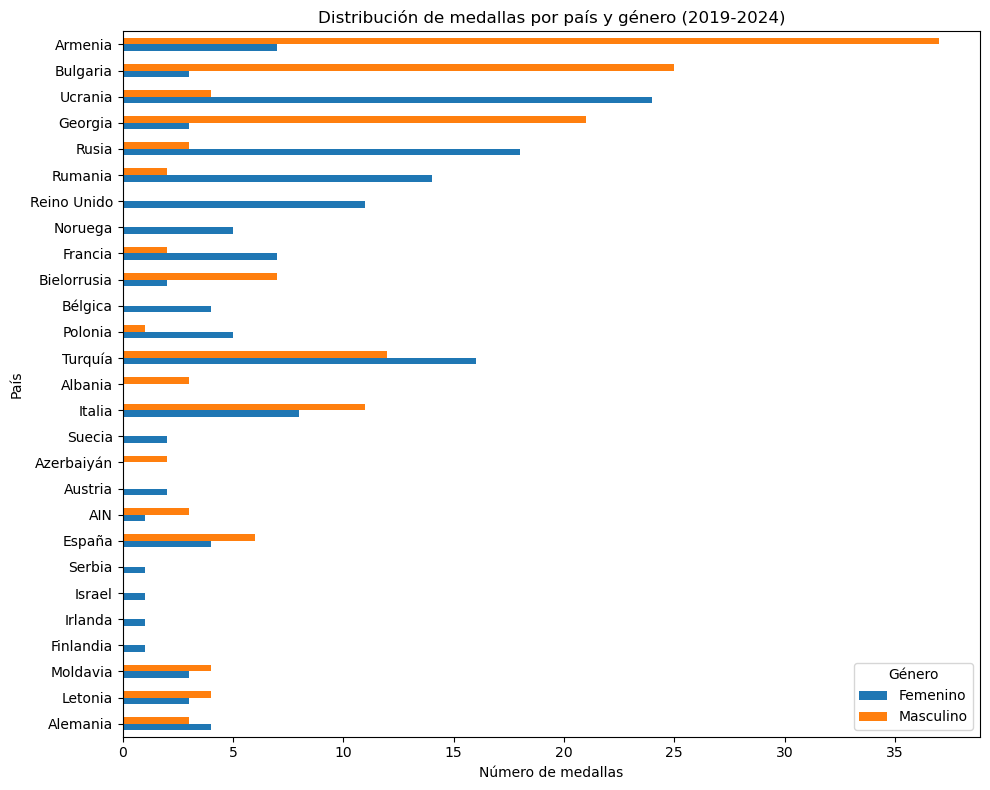

In [ ]:
# Visualizar la distribución de medallas por país y género.

medallas_genero[['Femenino', 'Masculino']].plot(
    kind='barh',
    figsize=(10, 8)
)

plt.title('Distribución de medallas por país y género (2019-2024)')
plt.xlabel('Número de medallas')
plt.ylabel('País')
plt.legend(title='Género')
plt.tight_layout()
plt.show()

Alemania, Letonia y Moldavia presentan la menor diferencia absoluta entre medallas femeninas y masculinas, con una diferencia de una medalla y un total de siete medallas por país.

Sin embargo, al analizar la distribución porcentual, Turquía presenta el mismo equilibrio proporcional (57,14 % frente a 42,86 %), pero con un volumen superior de 28 medallas. Esto demuestra que países con diferentes cantidades de medallas pueden presentar una distribución porcentual equivalente entre géneros.

Cabe señalar que el análisis considera únicamente las medallas obtenidas, sin disponer del número total de participantes por país y género. Por tanto, los resultados permiten evaluar el equilibrio en la distribución de medallas, pero no determinar la igualdad en las tasas de éxito deportivo.

### ¿En qué país es menor la diferencia entre el promedio de pesos totales conseguidos por atletas femeninos y masculinos?

In [ ]:
# Calcular la diferencia entre los promedios de peso total por país y género.

promedio_genero = df_final_2019_2024.groupby(
    ['País', 'Género']
)['Total'].mean().unstack()

promedio_genero = promedio_genero.dropna()

promedio_genero['Diferencia'] = abs(
    promedio_genero['Femenino'] - promedio_genero['Masculino']
)

promedio_genero = promedio_genero.sort_values('Diferencia')

promedio_genero.round(2)

Género,Femenino,Masculino,Diferencia
País,,,
Rumania,209.71,246.50,36.79
Ucrania,225.04,321.75,96.71
Alemania,222.75,325.00,102.25
Turquía,198.88,307.67,108.79
Francia,225.00,341.00,116.00
Polonia,206.80,324.00,117.20
Georgia,248.00,365.33,117.33
Letonia,221.67,342.00,120.33
Moldavia,237.67,363.75,126.08


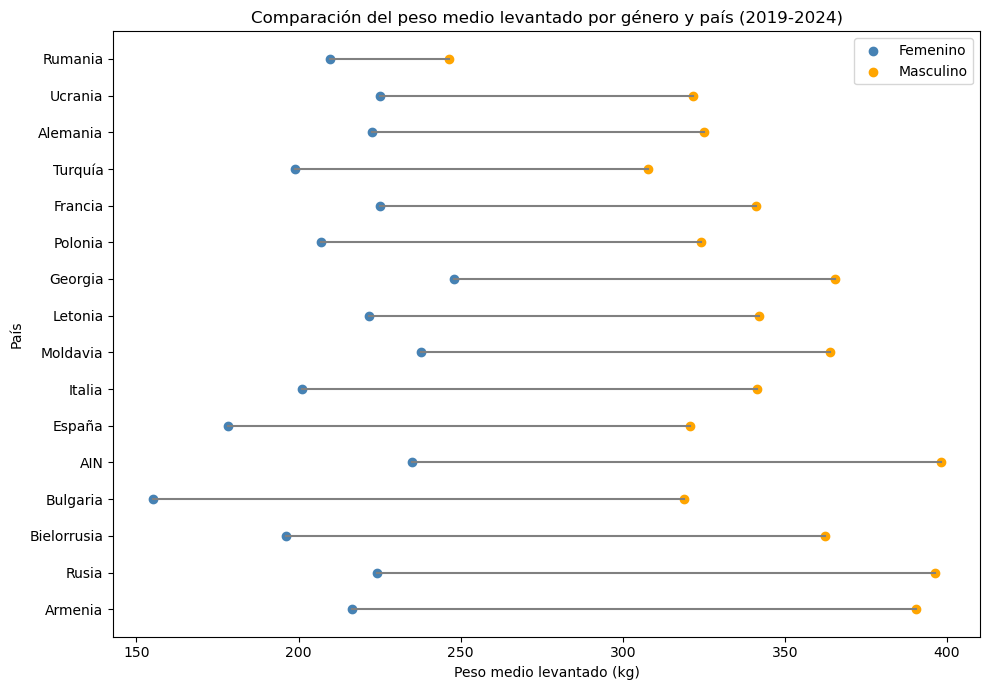

In [ ]:
# Comparar los promedios de peso total levantado por género y país.

plt.figure(figsize=(10, 7))

for pais in promedio_genero.index:
    femenino = promedio_genero.loc[pais, 'Femenino']
    masculino = promedio_genero.loc[pais, 'Masculino']

    plt.plot([femenino, masculino], [pais, pais], color='gray')
    plt.scatter(femenino, pais, color='steelblue')
    plt.scatter(masculino, pais, color='orange')

plt.scatter([], [], color='steelblue', label='Femenino')
plt.scatter([], [], color='orange', label='Masculino')

plt.title('Comparación del peso medio levantado por género y país (2019-2024)')
plt.xlabel('Peso medio levantado (kg)')
plt.ylabel('País')
plt.legend()

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Rumania presenta la menor diferencia entre los promedios de peso total levantado por medallistas femeninos y masculinos, con 36,79 kg (209,71 kg frente a 246,50 kg), seguida de Ucrania (96,71 kg) y Alemania (102,25 kg).

Sin embargo, este resultado debe interpretarse con cautela, ya que Rumania registra 14 medallas femeninas y únicamente 2 masculinas. Además, las comparaciones no están ajustadas por categorías de peso y el conjunto de datos incluye exclusivamente medallistas, por lo que las diferencias observadas no permiten determinar una mayor igualdad en el rendimiento deportivo entre géneros.

### Limitaciones del análisis respecto a la hipótesis de negocio

El análisis realizado permite conocer la distribución de medallas por país y género, así como las diferencias en los resultados deportivos de los Campeonatos Europeos de Halterofilia durante el periodo 2019-2024, considerando cinco ediciones efectivamente celebradas (2019 y 2021-2024).

Sin embargo, los datos disponibles se limitan a los deportistas medallistas y no incluyen indicadores sobre la evolución del número de practicantes, el interés del público o la popularidad del CrossFit.

Por tanto, los resultados permiten caracterizar el panorama competitivo de la halterofilia europea, pero no son suficientes para confirmar o rechazar la hipótesis de que el crecimiento del CrossFit está impulsando el interés por esta disciplina.

Para contrastar dicha hipótesis sería necesario complementar el análisis con indicadores de participación deportiva y evolución del interés por ambas disciplinas.